# 06 — Head Localization: Learned Sparse Mask

Learn a continuous mask over `(n_layers_tested, n_heads)` attention heads that selects the minimal set whose cross-language interchange (C++ source → Python destination) minimizes `KL(P_patched ∥ P_target)`.

**Objective:**
```
L = KL(P_patched ∥ P_target) + λ * Σ mask
```
- `P_patched`: next-token dist of dest prompt with mask-weighted head patch from source (C++)
- `P_target`: next-token dist of Python target prompt (same predicate as C++ source)
- Mask: `(n_layers_tested, n_heads)` values ∈ [0,1], initialized to 1, projected GD (no sigmoid)
- Selection: heads where mask > 0.5 after training

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

In [2]:
import os
import sys

sys.path.append("../")

##################################################################
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1,2,3,4,5,6,7"
# os.environ["CUDA_VISIBLE_DEVICES"] = "0,1"
##################################################################

import logging
import torch
import transformers

from rich.console import Console
from rich.theme import Theme

from src.utils import logging_utils
from src.utils import env_utils
import seaborn as sns

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme)


def rich_print(*args, **kwargs):
    console.print(*args, **kwargs)


logger = logging.getLogger(__name__)

logging.basicConfig(
    level=logging.DEBUG,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)

logger.info(f"{torch.__version__=}, {torch.version.cuda=}")
logger.info(
    f"{torch.cuda.is_available()=}, {torch.cuda.device_count()=}, {torch.cuda.get_device_name()=}"
)
logger.info(f"{transformers.__version__=}")

2026-03-18 22:02:45 __main__ INFO     torch.__version__='2.10.0+cu128', torch.version.cuda='12.8'
2026-03-18 22:02:45 __main__ INFO     torch.cuda.is_available()=True, torch.cuda.device_count()=8, torch.cuda.get_device_name()='NVIDIA A100 80GB PCIe'
2026-03-18 22:02:45 __main__ INFO     transformers.__version__='5.3.0'


## Model init

In [3]:
from src.models import ModelandTokenizer

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"

mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")
print(f"head_dim={mt.n_embd // mt.model.config.num_attention_heads}")
print(f"attn_module_name_format={mt.attn_module_name_format!r}")

2026-03-18 22:02:50 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-03-18 22:02:50 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-03-18 22:02:50 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7faf3bfb7050>
2026-03-18 22:02:50 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7faf3c934250> server_hostname='huggingface.co' timeout=10
2026-03-18 22:02:50 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7faf3bf2b4a0>
2026-03-18 22:02:50 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-03-18 22:02:50 httpcore.http11 DEBUG    send_request_headers.complete
2026-03-18 22:02:50 http

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-03-18 22:03:19 httpcore.connection DEBUG    close.started
2026-03-18 22:03:19 httpcore.connection DEBUG    close.complete
2026-03-18 22:03:19 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-03-18 22:03:19 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7faf3a356f30>
2026-03-18 22:03:19 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7faf3c934250> server_hostname='huggingface.co' timeout=10
2026-03-18 22:03:19 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7faf3bfd7f80>
2026-03-18 22:03:19 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-03-18 22:03:19 httpcore.http11 DEBUG    send_request_headers.complete
2026-03-18 22:03:19 httpcore.http11 DEBUG    send_request_body.started request=<Request [b'HE

## Load data

In [6]:
from src.goals.head_loc_data import HeadLocDataset

# Use "test" while mining is running; swap to mt.name.split("/")[-1] when done
MODEL_NAME = "test"

ds = HeadLocDataset.load(model_name=MODEL_NAME)
pivot_instances = ds.pivot_instances  # list[tuple[PredicatePair, PivotInstance]]

pairs_with_pivots = [p for p in ds.pairs if p.pivot_instances]
print(f"Predicates : {len(ds.samples)}")
print(f"Pairs total: {len(ds.pairs)}")
print(f"Pairs w/ pivots: {len(pairs_with_pivots)}")
print(f"Pivot instances: {len(pivot_instances)}")

2026-03-18 22:03:41 src.goals.head_loc_data INFO     Loaded 21 predicates, 110 pairs from /disk/u/arnab/Codes/Projects/goals/data/head_loc/pairs/test.json
Predicates : 21
Pairs total: 110
Pairs w/ pivots: 2
Pivot instances: 43


In [7]:
from rich.console import Console
from rich.table import Table

console = Console(width=100, highlight=False)
table = Table(title=f"Pairs with pivot instances ({MODEL_NAME})", highlight=False)
table.add_column("Destination", style="cyan")
table.add_column("Source (C++)", style="magenta")
table.add_column("Type", style="yellow")
table.add_column("# Pivots", style="green", justify="right")

for p in ds.pairs:
    if p.pivot_instances:
        table.add_row(
            p.destination_predicate,
            p.source_predicate,
            p.variable_type,
            str(len(p.pivot_instances)),
        )

console.print(table)

         Pairs with pivot instances (test)         
┏━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━━━┓
┃ Destination   ┃ Source (C++)  ┃ Type ┃ # Pivots ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━━━┩
│ is_upper      │ is_palindrome │ str  │       23 │
│ is_palindrome │ is_upper      │ str  │       20 │
└───────────────┴───────────────┴──────┴──────────┘

In [8]:
from src.goals.head_loc_pivot import build_cpp_prompt, build_python_prompt

# Pick the first pair that actually has pivot instances
pair, pi = next((p, pi) for p in ds.pairs for pi in p.pivot_instances)

print("PredicatePair:")
print(f"  destination_predicate : {pair.destination_predicate}  ← Python dest")
print(f"  source_predicate      : {pair.source_predicate}  ← C++ source / Python target")
print(f"  variable_type         : {pair.variable_type}")
print(f"  pivot count           : {len(pair.pivot_instances)}")

print("\nPivotInstance:")
print(f"  pivot_prefix     : {pi.pivot_prefix!r}")
print(f"  dest_top_token   : {pi.dest_top_token!r}")
print(f"  target_top_token : {pi.target_top_token!r}")
print(f"  tokens_diverge   : {pi.tokens_diverge}")

dest_sample = ds.get_sample(pair.destination_predicate)
targ_sample = ds.get_sample(pair.source_predicate)  # source_predicate = Python target

src_prompt  = build_cpp_prompt(mt, ds.get_sample(pair.source_predicate))
dest_prompt = build_python_prompt(mt, dest_sample, pivot_prefix=pi.pivot_prefix)
targ_prompt = build_python_prompt(mt, targ_sample, pivot_prefix=pi.pivot_prefix)

print("\n--- C++ source prompt ---")
rich_print(src_prompt)
print("\n--- Python dest prompt ---")
rich_print(dest_prompt)
print("\n--- Python target prompt  ---")
rich_print(targ_prompt)

PredicatePair:
  destination_predicate : is_upper  ← Python dest
  source_predicate      : is_palindrome  ← C++ source / Python target
  variable_type         : str
  pivot count           : 23

PivotInstance:
  pivot_prefix     : 's'
  dest_top_token   : '.is'
  target_top_token : ' =='
  tokens_diverge   : True

--- C++ source prompt ---


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax 
and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the C++ function below.<|im_end|>
<|im_start|>assistant
<code>
bool isPalindrome(string s) { return


--- Python dest prompt ---


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax 
and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Python function below.<|im_end|>
<|im_start|>assistant
<code>
def is_upper(s: str) -> bool:
    return s


--- Python target prompt  ---


<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax 
and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Complete the Python function below.<|im_end|>
<|im_start|>assistant
<code>
def is_palindrome(s: str) -> bool:
    return s

## Cache pivot data (one-time, ~2 forward passes per instance)

In [ ]:
from src.goals.head_loc_attn import cache_pivot_data

# LAYERS = list(range(0, mt.n_layer))
LAYERS = list(range(6, 40))

pivot_caches = cache_pivot_data(mt, pivot_instances, ds, layers=LAYERS)

print(f"Cached {len(pivot_caches)} instances")
c = pivot_caches[0]
print(f"per_head_deltas shape: {c.per_head_deltas.shape}")  # (n_layers, n_heads, n_embd)
print(f"log_p_target shape:    {c.log_p_target.shape}")

2026-03-18 23:23:34 src.goals.head_loc_attn INFO     cache_pivot_data: 43 instances | precompute_deltas=True


In [ ]:
# c

In [ ]:
mt.attn_module_name_format

'model.layers.{}.self_attn'

## Train the head mask

In [ ]:
from src.goals.head_loc_attn import train_head_mask

mask, history = train_head_mask(
    mt,
    pivot_caches,
    layers=LAYERS,
    n_epochs=100,
    lr=1e-2,
    lambda_sparse=20,
    batch_size=16,
)

n_heads = mt.model.config.num_attention_heads
print(f"\nFinal active heads: {mask.n_active()} / {len(LAYERS) * n_heads}")
print("Selected:", mask.selected_heads(LAYERS))

2026-03-18 23:06:58 src.goals.head_loc_attn INFO     train_head_mask: 64L × 40H = 2560 mask params | 43 instances | batch_size=16 (3 batches/epoch) | 100 epochs | lr=0.01 λ=20 | lazy_deltas=False
2026-03-18 23:07:08 src.goals.head_loc_attn INFO       Epoch   1/100: KL=19.8051  sparse=19.8116  total=39.6167  n_active=2560
2026-03-18 23:07:45 src.goals.head_loc_attn INFO       Epoch   5/100: KL=19.4278  sparse=17.6367  total=37.0645  n_active=2560
2026-03-18 23:08:33 src.goals.head_loc_attn INFO       Epoch  10/100: KL=18.7463  sparse=15.0035  total=33.7499  n_active=2560
2026-03-18 23:09:21 src.goals.head_loc_attn INFO       Epoch  15/100: KL=18.1104  sparse=12.4230  total=30.5334  n_active=2559
2026-03-18 23:10:08 src.goals.head_loc_attn INFO       Epoch  20/100: KL=17.5894  sparse=9.9215  total=27.5108  n_active=615
2026-03-18 23:10:55 src.goals.head_loc_attn INFO       Epoch  25/100: KL=17.1240  sparse=7.5761  total=24.7001  n_active=423
2026-03-18 23:11:42 src.goals.head_loc_attn IN

## Training curves

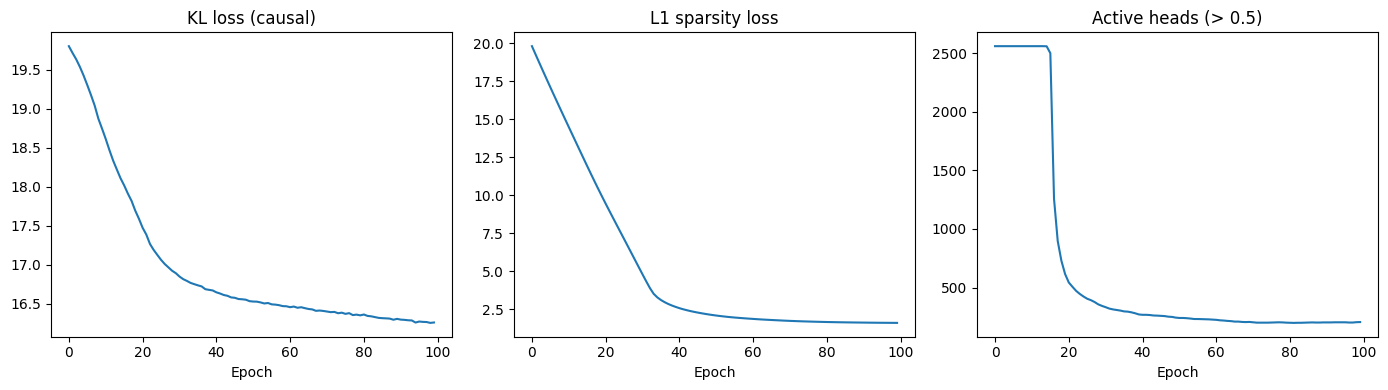

In [ ]:
from matplotlib import pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(history.loss_causal)
axes[0].set_title("KL loss (causal)")
axes[0].set_xlabel("Epoch")

axes[1].plot(history.loss_sparse)
axes[1].set_title("L1 sparsity loss")
axes[1].set_xlabel("Epoch")

axes[2].plot(history.n_active)
axes[2].set_title("Active heads (> 0.5)")
axes[2].set_xlabel("Epoch")

plt.tight_layout()
plt.show()

## Mask heatmap

2026-03-18 23:22:59 matplotlib.colorbar DEBUG    locator: <matplotlib.ticker.AutoLocator object at 0x7faed036ce90>


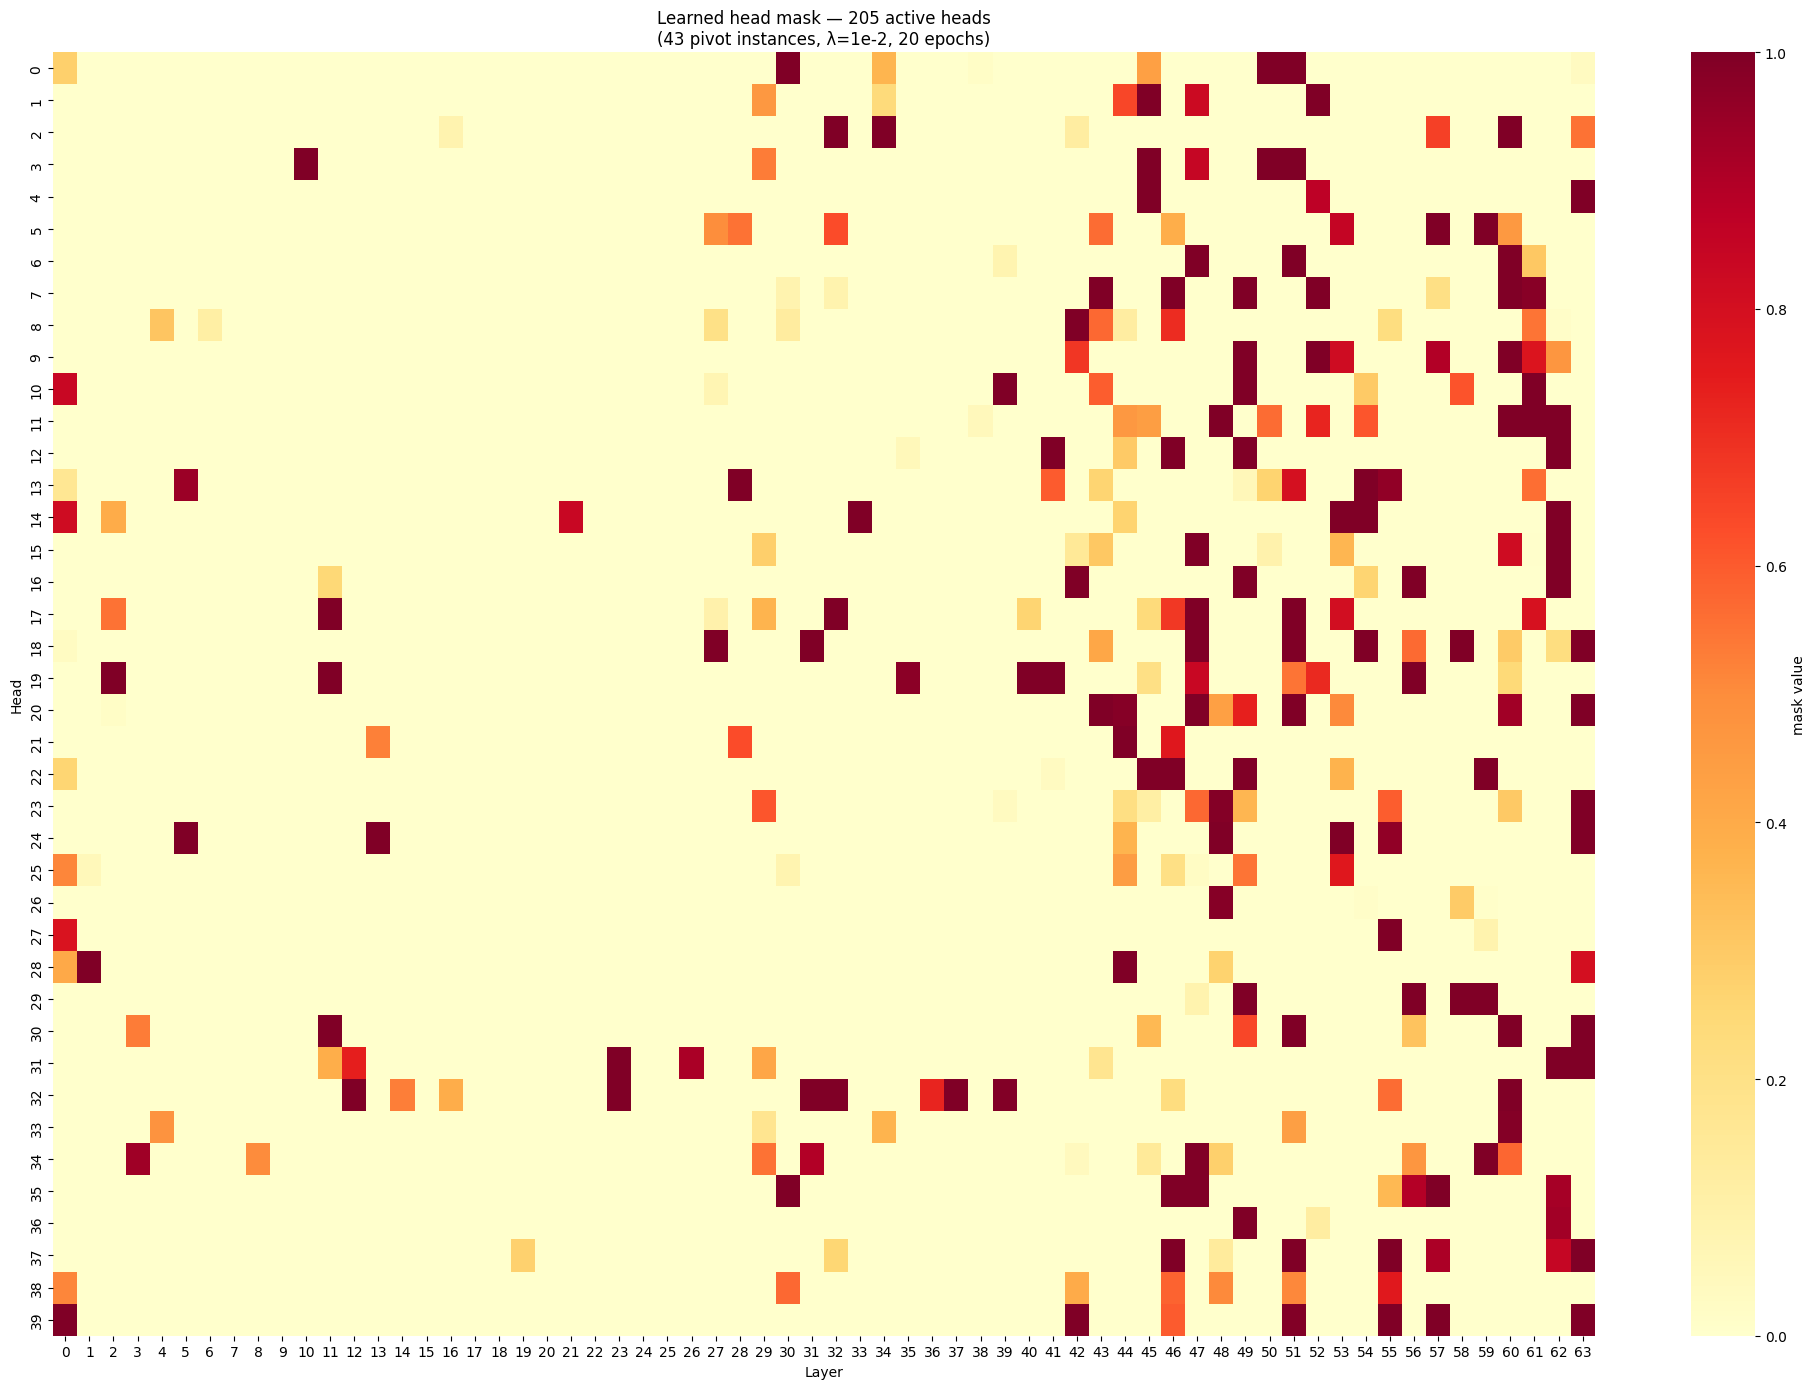


Top 10 heads by mask value:
  layer=59 head=22: 1.0000
  layer=1 head=28: 1.0000
  layer=49 head=10: 1.0000
  layer=45 head=22: 1.0000
  layer=48 head=24: 1.0000
  layer=30 head=0: 1.0000
  layer=54 head=14: 1.0000
  layer=31 head=32: 1.0000
  layer=54 head=13: 1.0000
  layer=59 head=5: 1.0000


In [ ]:
mask_vals = mask.values.detach().cpu().numpy()  # (n_layers_tested, n_heads)
import numpy as np

fig, ax = plt.subplots(figsize=(20, 14))
sns.heatmap(
    mask_vals.T, ax=ax, cmap="YlOrRd", vmin=0, vmax=1,
    xticklabels=[str(l) for l in LAYERS],
    yticklabels=range(n_heads),
    cbar_kws={"label": "mask value"},
)
ax.set_title(
    f"Learned head mask — {mask.n_active()} active heads\n"
    f"({len(pivot_instances)} pivot instances, λ=1e-2, 20 epochs)"
)
ax.set_xlabel("Layer")
ax.set_ylabel("Head")
plt.tight_layout()
plt.show()

print("\nTop 10 heads by mask value:")
flat = mask_vals.flatten()
for idx in np.argsort(flat)[::-1][:10]:
    li, h = divmod(int(idx), n_heads)
    print(f"  layer={LAYERS[li]} head={h}: {mask_vals[li, h]:.4f}")

## Sparsity sweep: λ vs. n_active vs. KL (Pareto frontier)

17:14:02 INFO src.goals.head_loc_attn — train_head_mask: 40L × 40H = 1600 mask params | 10 instances | 20 epochs | lr=0.01 λ=0.001
17:14:04 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.6388  sparse=1.5710  total=5.2098  n_active=1600
17:14:14 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.1130  sparse=1.4074  total=3.5204  n_active=1574
17:14:27 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=1.7670  sparse=1.2269  total=2.9938  n_active=1357
17:14:39 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=1.5683  sparse=1.0787  total=2.6470  n_active=1185
17:14:51 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.4358  sparse=0.9634  total=2.3993  n_active=1037
17:14:51 INFO src.goals.head_loc_attn — train_head_mask done: 1037 active heads → [(20, 3), (20, 4), (20, 5), (20, 11), (20, 15), (20, 18), (20, 25), (20, 27), (20, 28), (20, 33), (20, 34), (20, 39), (21, 1), (21, 4), (21, 6), (21, 8), (21, 9), (21, 11), (21, 13), (21, 15), (21, 18), (21, 26), (21, 27), (21, 31), (21,

  λ=1e-03: n_active=1037  KL=1.4358


17:14:53 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.5949  sparse=7.7937  total=11.3886  n_active=1600
17:15:03 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.0779  sparse=6.3495  total=8.4274  n_active=1507
17:15:14 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=1.7208  sparse=4.5194  total=6.2402  n_active=933
17:15:26 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=1.5331  sparse=3.2795  total=4.8126  n_active=665
17:15:38 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.4172  sparse=2.5283  total=3.9455  n_active=506
17:15:38 INFO src.goals.head_loc_attn — train_head_mask done: 506 active heads → [(21, 32), (22, 29), (23, 6), (23, 23), (23, 26), (23, 31), (23, 35), (25, 38), (26, 9), (26, 27), (26, 31), (27, 8), (27, 10), (27, 17), (27, 18), (27, 19), (27, 21), (27, 23), (28, 4), (28, 5), (28, 12), (28, 13), (28, 17), (28, 21), (28, 23), (28, 24), (28, 25), (29, 1), (29, 2), (29, 4), (29, 17), (29, 18), (29, 19), (29, 22), (29, 23), (29, 31), (29, 39), (30, 0),

  λ=5e-03: n_active= 506  KL=1.4172


17:15:40 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.5640  sparse=15.5110  total=19.0750  n_active=1600
17:15:49 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.0515  sparse=11.7952  total=13.8468  n_active=1445
17:16:01 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=1.7356  sparse=7.0230  total=8.7586  n_active=647
17:16:13 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=1.5843  sparse=4.2879  total=5.8722  n_active=388
17:16:24 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.4716  sparse=2.9599  total=4.4315  n_active=265
17:16:24 INFO src.goals.head_loc_attn — train_head_mask done: 265 active heads → [(23, 6), (27, 10), (27, 17), (27, 18), (28, 5), (28, 13), (29, 1), (29, 18), (29, 19), (29, 23), (30, 0), (30, 8), (30, 23), (30, 25), (30, 35), (30, 38), (31, 16), (31, 18), (31, 19), (31, 23), (31, 31), (31, 32), (31, 34), (32, 1), (32, 3), (32, 8), (32, 13), (32, 25), (32, 26), (32, 32), (32, 33), (33, 26), (33, 30), (33, 34), (34, 3), (34, 4), (34, 22), (34, 25

  λ=1e-02: n_active= 265  KL=1.4716


17:16:27 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.5192  sparse=30.8728  total=34.3920  n_active=1600
17:16:36 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.1125  sparse=21.8097  total=23.9222  n_active=1349
17:16:48 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=1.8070  sparse=10.2562  total=12.0632  n_active=381
17:17:00 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=1.6782  sparse=4.9416  total=6.6198  n_active=202
17:17:13 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.6196  sparse=3.2284  total=4.8480  n_active=134
17:17:13 INFO src.goals.head_loc_attn — train_head_mask done: 134 active heads → [(27, 10), (29, 1), (29, 18), (30, 8), (30, 23), (30, 35), (30, 38), (31, 16), (31, 18), (31, 19), (31, 23), (31, 32), (31, 34), (32, 3), (33, 34), (34, 22), (34, 25), (35, 13), (35, 39), (38, 0), (38, 7), (39, 6), (39, 8), (39, 9), (39, 31), (39, 32), (39, 34), (40, 3), (40, 8), (40, 11), (40, 13), (40, 32), (40, 34), (41, 6), (41, 9), (41, 12), (42, 11), (43, 5)

  λ=2e-02: n_active= 134  KL=1.6196


17:17:15 INFO src.goals.head_loc_attn —   Epoch   1/20: KL=3.5004  sparse=76.7545  total=80.2549  n_active=1600
17:17:25 INFO src.goals.head_loc_attn —   Epoch   5/20: KL=2.3505  sparse=49.4677  total=51.8182  n_active=1125
17:17:37 INFO src.goals.head_loc_attn —   Epoch  10/20: KL=2.0425  sparse=15.5258  total=17.5683  n_active=139
17:17:52 INFO src.goals.head_loc_attn —   Epoch  15/20: KL=2.0015  sparse=5.2949  total=7.2964  n_active=79
17:18:04 INFO src.goals.head_loc_attn —   Epoch  20/20: KL=1.9817  sparse=3.4552  total=5.4369  n_active=64
17:18:04 INFO src.goals.head_loc_attn — train_head_mask done: 64 active heads → [(30, 8), (30, 35), (31, 18), (31, 32), (38, 0), (39, 8), (39, 9), (39, 31), (39, 32), (43, 15), (44, 21), (45, 1), (45, 3), (45, 17), (45, 18), (45, 31), (46, 7), (46, 8), (46, 12), (46, 19), (46, 20), (46, 25), (46, 35), (46, 39), (47, 8), (47, 32), (47, 33), (47, 34), (48, 24), (48, 25), (48, 26), (49, 6), (49, 9), (49, 10), (49, 12), (49, 13), (49, 15), (49, 16),

  λ=5e-02: n_active=  64  KL=1.9817


17:18:04 DEBUG matplotlib.font_manager — findfont: score(FontEntry(fname='/usr/share/fonts/truetype/noto/NotoSansMandaic-Regular.ttf', name='Noto Sans Mandaic', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
17:18:04 DEBUG matplotlib.font_manager — findfont: score(FontEntry(fname='/usr/share/fonts/truetype/freefont/FreeMonoBoldOblique.ttf', name='FreeMono', style='oblique', variant='normal', weight=700, stretch='normal', size='scalable')) = 11.335
17:18:04 DEBUG matplotlib.font_manager — findfont: score(FontEntry(fname='/usr/share/fonts/opentype/tlwg/TlwgTypewriter-Oblique.otf', name='Tlwg Typewriter', style='oblique', variant='normal', weight=400, stretch='normal', size='scalable')) = 11.05
17:18:04 DEBUG matplotlib.font_manager — findfont: score(FontEntry(fname='/usr/share/fonts/opentype/ipafont-mincho/ipamp.ttf', name='IPAPMincho', style='normal', variant='normal', weight=400, stretch='normal', size='scalable')) = 10.05
17:18:04 DEBUG matpl

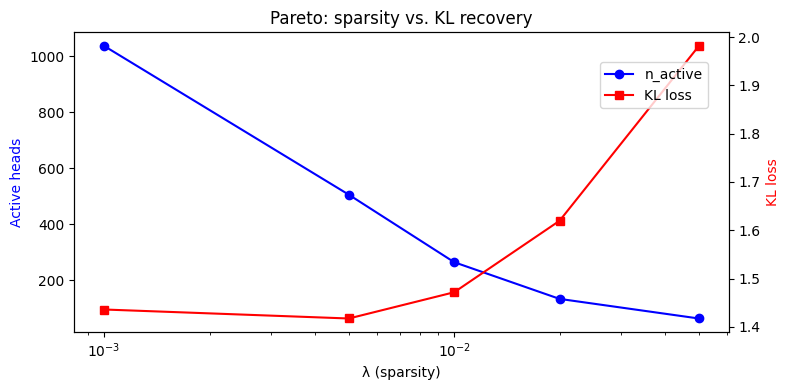

In [ ]:
# lambdas = [1e-3, 5e-3, 1e-2, 2e-2, 5e-2]
lambdas = [1, 5, 10, 20, 50, 75, 100]
pareto = []

for lam in lambdas:
    m, h = train_head_mask(mt, pivot_caches, layers=LAYERS, n_epochs=20, lr=1e-2, lambda_sparse=lam)
    pareto.append((lam, m.n_active(), h.loss_causal[-1]))
    print(f"  λ={lam:.0e}: n_active={m.n_active():4d}  KL={h.loss_causal[-1]:.4f}")

lams, n_acts, kls = zip(*pareto)
fig, ax1 = plt.subplots(figsize=(8, 4))
ax2 = ax1.twinx()
ax1.semilogx(lams, n_acts, "b-o", label="n_active")
ax2.semilogx(lams, kls, "r-s", label="KL loss")
ax1.set_xlabel("λ (sparsity)")
ax1.set_ylabel("Active heads", color="b")
ax2.set_ylabel("KL loss", color="r")
ax1.set_title("Pareto: sparsity vs. KL recovery")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.85))
plt.tight_layout()
plt.show()

## Qualitative Evaluation

In [ ]:
from src.goals.head_loc_attn import HeadMask, forward_with_masked_patch
from src.tokens import prepare_input

MAX_NEW_TOKENS = 32

_nl_ids = mt.tokenizer.encode("\n", add_special_tokens=False)
STOP_IDS = {mt.tokenizer.eos_token_id} | set(_nl_ids)


def greedy_generate_baseline(mt, input_ids, attention_mask, max_new_tokens=MAX_NEW_TOKENS):
    """Plain greedy generation — no patch."""
    input_ids = input_ids.clone()
    attention_mask = attention_mask.clone()
    generated = []
    with torch.no_grad():
        for _ in range(max_new_tokens):
            out = mt._model(input_ids=input_ids, attention_mask=attention_mask)
            next_tok = int(out.logits[0, -1, :].argmax())
            generated.append(next_tok)
            if next_tok in STOP_IDS:
                break
            next_tok_t = torch.tensor([[next_tok]], device=input_ids.device)
            ones = torch.ones((1, 1), dtype=attention_mask.dtype, device=attention_mask.device)
            input_ids = torch.cat([input_ids, next_tok_t], dim=1)
            attention_mask = torch.cat([attention_mask, ones], dim=1)
    return mt.tokenizer.decode(generated, skip_special_tokens=True).rstrip()


def patched_generate(mt, pivot_cache, mask, layers, max_new_tokens=MAX_NEW_TOKENS, threshold=0.5):
    """Greedy generation with binary-thresholded head patch applied at every step."""
    binary_mask = HeadMask(mask.values.shape[0], mask.values.shape[1])
    with torch.no_grad():
        binary_mask.values.copy_((mask.values.detach() > threshold).float())

    dest_inputs = prepare_input([pivot_cache.dest_prompt], tokenizer=mt)
    input_ids = dest_inputs["input_ids"].clone()
    attention_mask = dest_inputs["attention_mask"].clone()

    generated = []
    for _ in range(max_new_tokens):
        inputs = {"input_ids": input_ids, "attention_mask": attention_mask}
        with torch.no_grad():
            logits = forward_with_masked_patch(
                mt, inputs, pivot_cache.per_head_deltas, binary_mask, layers
            )
        next_tok = int(logits.argmax())
        generated.append(next_tok)
        if next_tok in STOP_IDS:
            break
        next_tok_t = torch.tensor([[next_tok]], device=input_ids.device)
        ones = torch.ones((1, 1), dtype=attention_mask.dtype, device=attention_mask.device)
        input_ids = torch.cat([input_ids, next_tok_t], dim=1)
        attention_mask = torch.cat([attention_mask, ones], dim=1)

    return mt.tokenizer.decode(generated, skip_special_tokens=True).rstrip()


def _first_word(s):
    parts = s.split()
    return parts[0] if parts else "?"


# ── Evaluation loop ──────────────────────────────────────────────────────────
print(f"Binary mask threshold=0.5 → {mask.n_active()} active heads\n")
print("=" * 80)

n_match = 0
for i, (cache, (pair, pi)) in enumerate(zip(pivot_caches, pivot_instances)):
    targ_sample = ds.get_sample(pair.source_predicate)  # source = C++ = Python target
    targ_prompt = build_python_prompt(mt, targ_sample, pivot_prefix=pi.pivot_prefix)
    targ_inputs = prepare_input(prompts=[targ_prompt], tokenizer=mt)

    dest_inputs = prepare_input(prompts=[cache.dest_prompt], tokenizer=mt)
    dest_baseline = greedy_generate_baseline(
        mt, dest_inputs["input_ids"], dest_inputs["attention_mask"]
    )
    targ_baseline = greedy_generate_baseline(
        mt, targ_inputs["input_ids"], targ_inputs["attention_mask"]
    )
    dest_patched = patched_generate(mt, cache, mask, layers=LAYERS)

    ret_prefix = f"return {pi.pivot_prefix}" if pi.pivot_prefix else "return"
    patched_w0 = _first_word(dest_patched)
    target_w0  = _first_word(targ_baseline)
    hit = patched_w0 == target_w0
    n_match += int(hit)
    marker = "\u2713" if hit else "\u2717"

    print(f"[{i+1:02d}] {pair.destination_predicate} \u2190 {pair.source_predicate}  (prefix={pi.pivot_prefix!r})")
    print(f"  dest baseline : {ret_prefix} {dest_baseline}")
    print(f"  dest patched  : {ret_prefix} {dest_patched}")
    print(f"  target        : {ret_prefix} {targ_baseline}")
    print(f"  first-token   : {marker}  patched={patched_w0!r}  target={target_w0!r}")
    print()

print(f"First-token match: {n_match}/{len(pivot_caches)}")